# Compare Negative Sampling Strategies for Random Forest Training

This notebook compares two negative sampling strategies for training a RandomForest classifier on cell-pair matching features:

1. **Hard Negative Mining (top-k)**: for each positive pair, select the top-k most confusing negatives.
2. **All Candidates (top-N + spatial window)**: choose top-N closest-by-centroid candidates and keep those within a spatial window.

Outputs:
- Per-strategy evaluation figures (ROC, PR, confusion matrix), saved as PDF and displayed inline.
- Feature distribution comparison (positive vs negative), saved as PDF and displayed inline.
- A summary table comparing strategies by F1/Precision/Recall/AUC.

In [1]:
import numpy as np
import pandas as pd
import re

import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score, accuracy_score,
    roc_curve, precision_recall_curve, confusion_matrix, auc
)
from scipy import stats
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 7
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["figure.dpi"] = 300
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["text.usetex"] = False
plt.rcParams["mathtext.default"] = "regular"

In [3]:
from cell_matching_utils import (
    load_cells_from_csv_files,
    dtw_distance_gpu_single,
    get_cluster_cells,
    compute_ot_cost_matrix,
    solve_optimal_transport,
    DTW_NORM_DIVISOR,
    OT_NORM_DIVISOR
)

import cell_matching_utils as recon_module

In [4]:
FEATURE_NAMES = ["dtw_loss", "ot_loss", "area_loss", "aspect_ratio_loss", "centroid_displacement"]

def solve_ot_with_adaptive_reg(C, weights_a, weights_b):
    adaptive_reg = max(np.max(C) / 10.0, 50000.0)
    original_reg = recon_module.SINKHORN_REG
    recon_module.SINKHORN_REG = adaptive_reg
    try:
        return recon_module.solve_optimal_transport(C, weights_a, weights_b, use_gpu=True)
    finally:
        recon_module.SINKHORN_REG = original_reg
        

In [5]:
def load_golden_pairings(csv_path: str) -> pd.DataFrame:
    """Load golden standard pairings from CSV."""
    return pd.read_csv(csv_path)

In [6]:
def calculate_metrics(cell1, cell2, cells_by_slice):
    metrics = {}
    
    if hasattr(cell1, "contour_points_200") and hasattr(cell2, "contour_points_200"):
        dtw_raw = dtw_distance_gpu_single(cell1.contour_points_200, cell2.contour_points_200)
    else:
        dtw_raw = dtw_distance_gpu_single(cell1.contour_points, cell2.contour_points)
    metrics["dtw_loss"] = min(10.0, dtw_raw / DTW_NORM_DIVISOR * 10.0)
    
    cluster1 = get_cluster_cells(cell1, cells_by_slice)
    cluster2 = get_cluster_cells(cell2, cells_by_slice)
    if len(cluster1) > 1 and len(cluster2) > 1:
        C = compute_ot_cost_matrix(cluster1, cluster2)
        areas1 = np.array([c.area for c in cluster1])
        areas2 = np.array([c.area for c in cluster2])
        weights1 = areas1 / areas1.sum()
        weights2 = areas2 / areas2.sum()
        ot_raw, _ = solve_ot_with_adaptive_reg(C, weights1, weights2)
        metrics["ot_loss"] = min(10.0, ot_raw / OT_NORM_DIVISOR * 10.0)
    else:
        metrics["ot_loss"] = 0.0
    
    area_ratio = min(cell1.area, cell2.area) / max(cell1.area, cell2.area)
    metrics["area_loss"] = (1.0 - area_ratio) * 10.0
    
    metrics["aspect_ratio_loss"] = min(10.0, abs(cell1.aspect_ratio - cell2.aspect_ratio) * 2.5)
    metrics["centroid_displacement"] = np.linalg.norm(cell2.centroid - cell1.centroid)
    
    return metrics

In [7]:
def construct_dataset_hard_negatives(golden_df, cells_by_slice, top_k=20):
    positive_samples = []
    negative_samples = []
    
    for idx, row in golden_df.iterrows():
        start_layer = row["Start_layer"]
        end_layer = row["End_layer"]
        start_cell_id = row["Start_cell"]
        end_cell_id = row["End_cell"]
        
        if end_layer - start_layer != 1:
            continue
        
        cell1 = next((c for c in cells_by_slice.get(start_layer, []) if c.cell_id == start_cell_id), None)
        cell2 = next((c for c in cells_by_slice.get(end_layer, []) if c.cell_id == end_cell_id), None)
        if not cell1 or not cell2:
            continue
        
        m_pos = calculate_metrics(cell1, cell2, cells_by_slice)
        m_pos["label"] = 1
        positive_samples.append(m_pos)
        
        candidates = cells_by_slice.get(end_layer, [])
        pre_filtered = []
        for cand in candidates:
            if cand.cell_id == end_cell_id:
                continue
            centroid_dist = np.linalg.norm(cand.centroid - cell1.centroid)
            area_ratio = min(cell1.area, cand.area) / max(cell1.area, cand.area)
            quick_score = centroid_dist + (1.0 - area_ratio) * 100.0
            pre_filtered.append((cand, quick_score))
        
        pre_filtered.sort(key=lambda x: x[1])
        candidates_to_evaluate = [c for c, _ in pre_filtered[:3 * top_k]]
        
        scored = []
        for cand in candidates_to_evaluate:
            m = calculate_metrics(cell1, cand, cells_by_slice)
            total_loss = m["dtw_loss"] + m["ot_loss"] + m["area_loss"]
            scored.append((cand, m, total_loss))
        
        scored.sort(key=lambda x: x[2])
        for _, m, _ in scored[:top_k]:
            m["label"] = 0
            negative_samples.append(m)
    
    print(f"Hard Mining (top-{top_k}): {len(positive_samples)} pos, {len(negative_samples)} neg")
    return pd.DataFrame(positive_samples + negative_samples)

In [8]:
def construct_dataset_all_candidates(golden_df, cells_by_slice, top_n=20, window_size=100):
    positive_samples = []
    negative_samples = []
    
    for idx, row in golden_df.iterrows():
        start_layer = row["Start_layer"]
        end_layer = row["End_layer"]
        start_cell_id = row["Start_cell"]
        end_cell_id = row["End_cell"]
        
        if end_layer - start_layer != 1:
            continue
        
        cell1 = next((c for c in cells_by_slice.get(start_layer, []) if c.cell_id == start_cell_id), None)
        cell2 = next((c for c in cells_by_slice.get(end_layer, []) if c.cell_id == end_cell_id), None)
        if not cell1 or not cell2:
            continue
        
        m_pos = calculate_metrics(cell1, cell2, cells_by_slice)
        m_pos["label"] = 1
        positive_samples.append(m_pos)
        
        candidates = cells_by_slice.get(end_layer, [])
        centroid_distances = []
        for cand in candidates:
            if cand.cell_id == end_cell_id:
                continue
            centroid_dist = np.linalg.norm(cand.centroid - cell1.centroid)
            centroid_distances.append((cand, centroid_dist))
        
        centroid_distances.sort(key=lambda x: x[1])
        top_candidates = [cand for cand, _ in centroid_distances[:top_n]]
        
        window_half = window_size / 2.0
        cx1, cy1 = cell1.centroid
        
        for cand in top_candidates:
            cx2, cy2 = cand.centroid
            if abs(cx2 - cx1) <= window_half and abs(cy2 - cy1) <= window_half:
                m = calculate_metrics(cell1, cand, cells_by_slice)
                m["label"] = 0
                negative_samples.append(m)
    
    print(f"All Candidates (top-{top_n}, {window_size}px): {len(positive_samples)} pos, {len(negative_samples)} neg")
    return pd.DataFrame(positive_samples + negative_samples)

In [9]:
def plot_strategy_analysis(df, strategy_name, y_pred_proba, best_threshold, best_metrics, output_dir="."):
    y = df["label"].values
    
    fig = plt.figure(figsize=(7.5, 2.5))
    gs = fig.add_gridspec(1, 3, hspace=0.35, wspace=0.35)
    
    ax1 = fig.add_subplot(gs[0, 0])
    fpr, tpr, _ = roc_curve(y, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    ax1.plot(fpr, tpr, color="#2E86AB", lw=1.5, label=f"AUC = {roc_auc:.3f}")
    ax1.plot([0, 1], [0, 1], "k--", lw=0.8, alpha=0.3)
    ax1.set_xlabel("False Positive Rate", fontsize=7)
    ax1.set_ylabel("True Positive Rate", fontsize=7)
    ax1.set_title("ROC Curve", fontsize=8, fontweight="bold")
    ax1.legend(fontsize=6, loc="lower right")
    ax1.grid(True, alpha=0.3, linewidth=0.5)
    ax1.set_xlim([-0.02, 1.02])
    ax1.set_ylim([-0.02, 1.02])
    
    ax2 = fig.add_subplot(gs[0, 1])
    precision_curve, recall_curve, _ = precision_recall_curve(y, y_pred_proba)
    pr_auc = auc(recall_curve, precision_curve)
    ax2.plot(recall_curve, precision_curve, color="#A23B72", lw=1.5, label=f"AP = {pr_auc:.3f}")
    ax2.set_xlabel("Recall", fontsize=7)
    ax2.set_ylabel("Precision", fontsize=7)
    ax2.set_title("Precision-Recall Curve", fontsize=8, fontweight="bold")
    ax2.legend(fontsize=6, loc="lower left")
    ax2.grid(True, alpha=0.3, linewidth=0.5)
    ax2.set_xlim([-0.02, 1.02])
    ax2.set_ylim([-0.02, 1.02])
    
    ax3 = fig.add_subplot(gs[0, 2])
    y_pred_opt = (y_pred_proba >= best_threshold).astype(int)
    cm = confusion_matrix(y, y_pred_opt)
    cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    
    ax3.imshow(cm_normalized, interpolation="nearest", cmap="Blues", vmin=0, vmax=1)
    ax3.set_xticks([0, 1])
    ax3.set_yticks([0, 1])
    ax3.set_xticklabels(["Negative", "Positive"], fontsize=7)
    ax3.set_yticklabels(["Negative", "Positive"], fontsize=7)
    ax3.set_xlabel("Predicted", fontsize=7)
    ax3.set_ylabel("True", fontsize=7)
    ax3.set_title("Confusion Matrix", fontsize=8, fontweight="bold")
    
    for i in range(2):
        for j in range(2):
            text_color = "white" if cm_normalized[i, j] > 0.5 else "black"
            ax3.text(j, i, f"{cm[i, j]}\n({cm_normalized[i, j]:.2%})",
                    ha="center", va="center", color=text_color, fontsize=6.5)
    
    fig.suptitle(
        f"{strategy_name}\nF1={best_metrics['f1']:.4f} | "
        f"Precision={best_metrics['precision']:.4f} | "
        f"Recall={best_metrics['recall']:.4f} | AUC={roc_auc:.4f}",
        fontsize=9, fontweight="bold", y=1.05)
    
    fig.savefig(f"{output_dir}/strategy_analysis_{strategy_name}.pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

In [10]:
def evaluate_strategy(df, strategy_name, output_dir="."):
    X = df[FEATURE_NAMES].values
    y = df["label"].values
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, 
                                class_weight="balanced", n_jobs=-1)
    
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    y_pred_proba = cross_val_predict(rf, X_scaled, y, cv=cv, method="predict_proba")[:, 1]
    
    best_threshold = 0.5
    best_f1 = 0
    best_metrics = None
    
    for thr in np.arange(0.10, 0.95, 0.05):
        y_pred = (y_pred_proba >= thr).astype(int)
        f1 = f1_score(y, y_pred)
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = thr
            best_metrics = {
                "accuracy": accuracy_score(y, y_pred),
                "precision": precision_score(y, y_pred),
                "recall": recall_score(y, y_pred),
                "f1": f1
            }
    
    plot_strategy_analysis(df, strategy_name, y_pred_proba, best_threshold, best_metrics, output_dir)
    
    return {
        "strategy": strategy_name,
        "n_samples": len(df),
        "n_positive": (y == 1).sum(),
        "n_negative": (y == 0).sum(),
        "pos_neg_ratio": f"1:{(y == 0).sum() / (y == 1).sum():.1f}",
        "optimal_threshold": best_threshold,
        "accuracy": best_metrics["accuracy"],
        "precision": best_metrics["precision"],
        "recall": best_metrics["recall"],
        "f1": best_metrics["f1"],
        "auc": roc_auc_score(y, y_pred_proba)
    }

In [11]:
def analyze_positive_negative_distributions(df, strategy_name, output_dir="."):
    df_pos = df[df["label"] == 1]
    df_neg = df[df["label"] == 0]
    
    fig, axes = plt.subplots(2, 3, figsize=(11, 7))
    feature_names = ["DTW Loss", "OT Loss", "Area Loss", "Aspect Ratio Loss", "Centroid Distance"]
    
    for idx, (feat_name, display_name) in enumerate(zip(FEATURE_NAMES, feature_names)):
        ax = axes[idx // 3, idx % 3]
        pos_vals = df_pos[feat_name].values
        neg_vals = df_neg[feat_name].values
        
        bp = ax.boxplot([pos_vals, neg_vals], positions=[1, 2], widths=0.5, patch_artist=True,
                        showfliers=False, boxprops=dict(linewidth=0.8),
                        medianprops=dict(linewidth=1.5, color="black"),
                        whiskerprops=dict(linewidth=0.8), capprops=dict(linewidth=0.8))
        
        bp["boxes"][0].set_facecolor("#06A77D")
        bp["boxes"][0].set_alpha(0.7)
        bp["boxes"][1].set_facecolor("#D62246")
        bp["boxes"][1].set_alpha(0.7)
        
        ax.set_xticks([1, 2])
        ax.set_xticklabels(["Positive", "Negative"], fontsize=7)
        ax.set_ylabel(display_name, fontsize=7, fontweight="bold")
        ax.set_title(f"{display_name} Distribution", fontsize=8, fontweight="bold")
        ax.grid(True, alpha=0.3, linewidth=0.5, axis="y")
        
        t_stat, p_value = stats.ttest_ind(pos_vals, neg_vals, equal_var=False)
        sig = "***" if p_value < 0.001 else "**" if p_value < 0.01 else "*" if p_value < 0.05 else "ns"
        y0, y1 = ax.get_ylim()
        ax.text(1.5, y0 + 0.95 * (y1 - y0), f"p={p_value:.1e} {sig}",
               ha="center", va="top", fontsize=8, fontweight="bold",
               bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.35, edgecolor="none"))
    
    fig.delaxes(axes[1, 2])
    fig.suptitle(f"{strategy_name}: Feature Distributions", fontsize=10, fontweight="bold", y=0.995)
    fig.tight_layout()
    fig.savefig(f"{output_dir}/{strategy_name}_feature_distributions.pdf", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

In [12]:
GOLDEN_PAIRING_CSV = "High_confidence_pairing_4nums_fullnames.csv"
CELL_FOLDER = "cell-002_processed"
OUTPUT_DIR = "."

HARD_NEGATIVE_TOPK_LIST = [5, 10, 20]
ALL_CANDIDATES_CONFIGS = [
    (20, 100),  # (top_n, window_size)
    (20, 150),
]

In [13]:
golden_df = load_golden_pairings(GOLDEN_PAIRING_CSV)
cells_by_slice = load_cells_from_csv_files(CELL_FOLDER)

print(f"Loaded {len(golden_df)} pairings, {sum(len(cells) for cells in cells_by_slice.values())} cells")

Loading from cell-002_processed: found 15 CSV files


Loading CSV files: 100%|██████████| 15/15 [01:17<00:00,  5.15s/it]


Total cells loaded: 12009
Loaded 340 pairings, 12009 cells


Hard Mining (top-5): 336 pos, 1680 neg


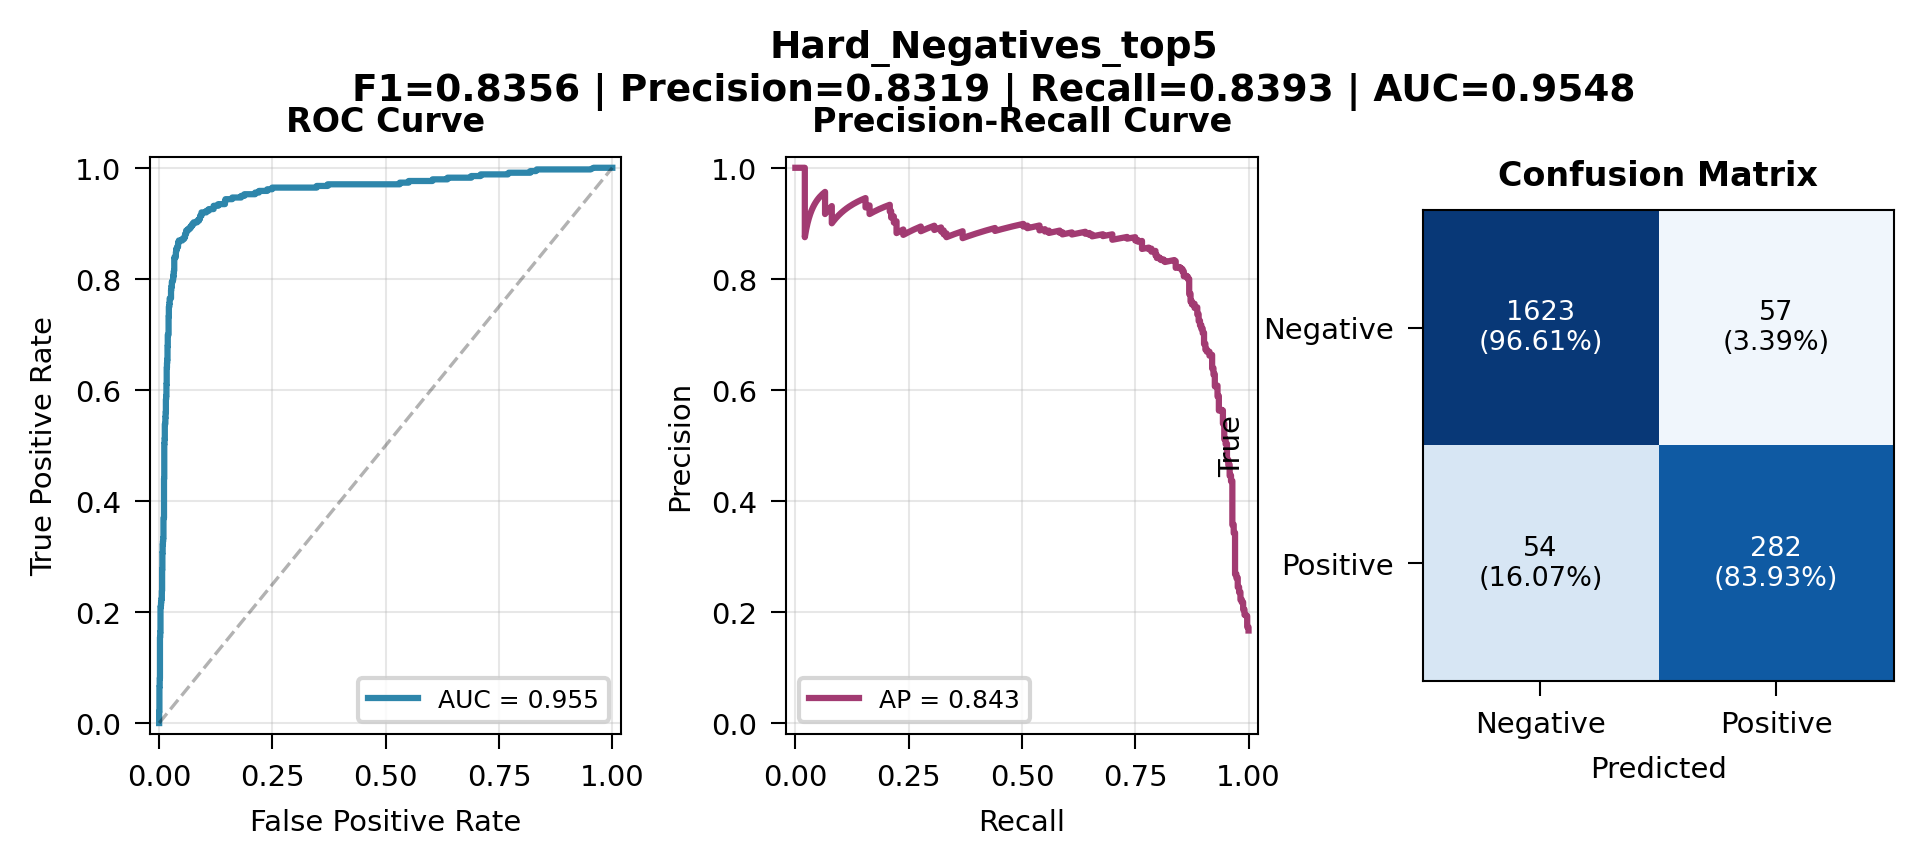

Hard Mining (top-10): 336 pos, 3360 neg


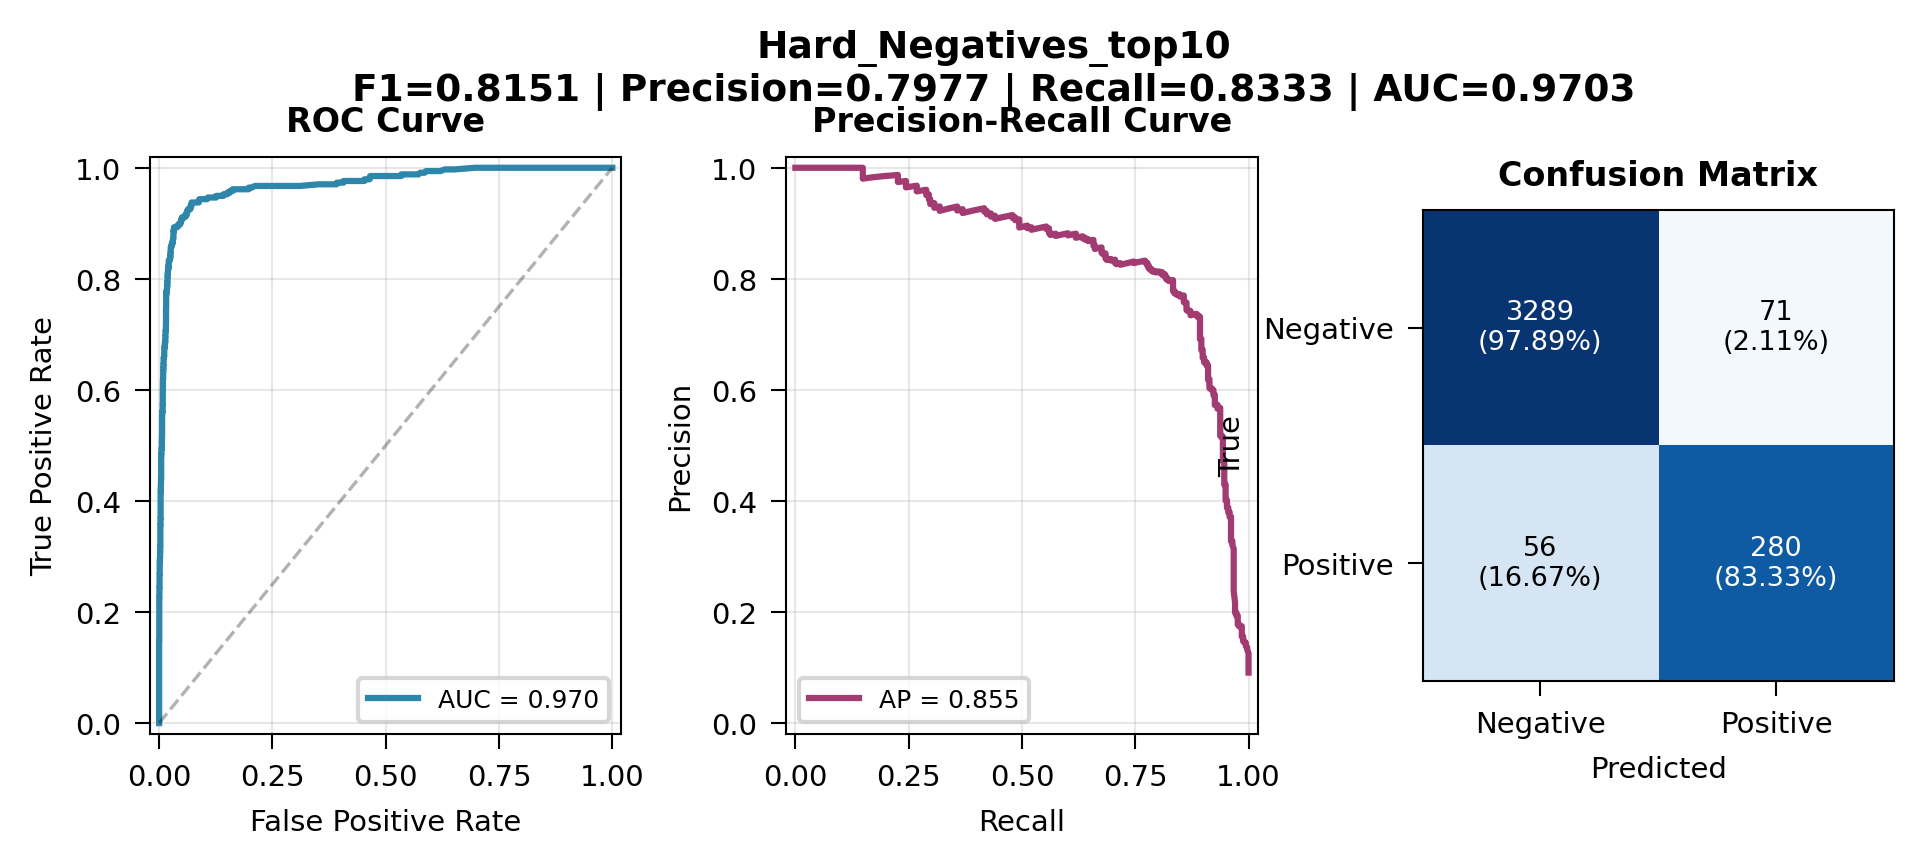

Hard Mining (top-20): 336 pos, 6720 neg


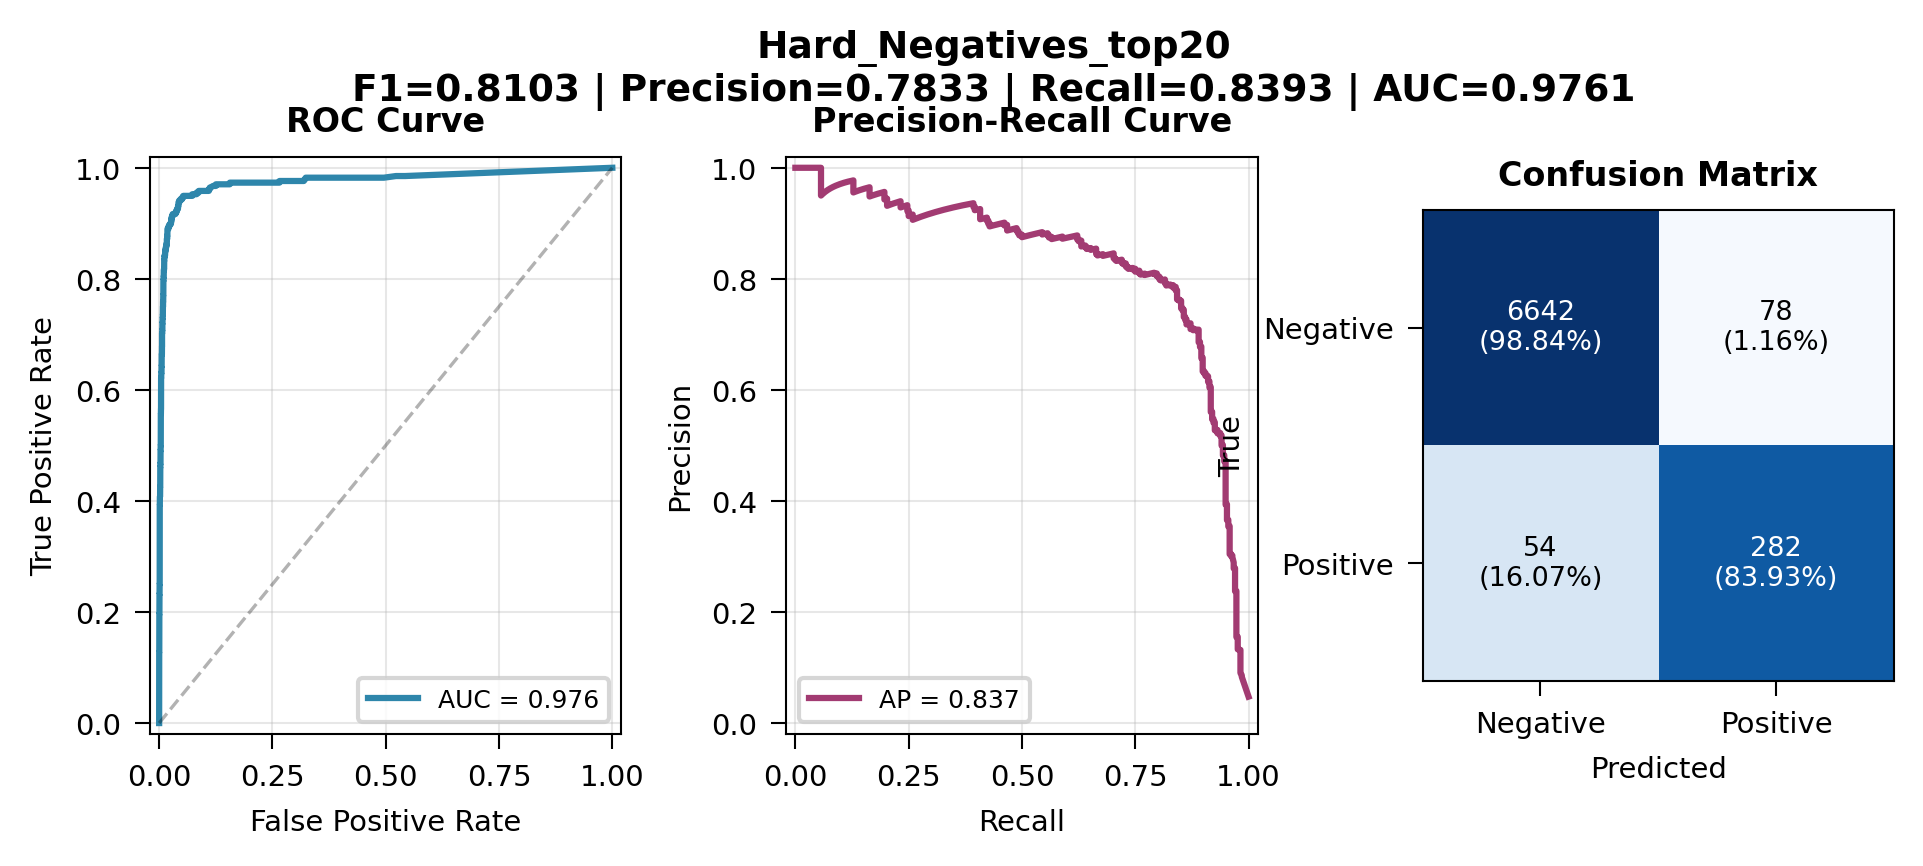

In [14]:
results = []
datasets = {}

for top_k in HARD_NEGATIVE_TOPK_LIST:
    df = construct_dataset_hard_negatives(golden_df, cells_by_slice, top_k=top_k)
    res = evaluate_strategy(df, f"Hard_Negatives_top{top_k}", output_dir=OUTPUT_DIR)
    results.append(res)
    if top_k == 5:
        datasets["Hard_Negatives_top5"] = df

All Candidates (top-20, 100px): 336 pos, 1403 neg


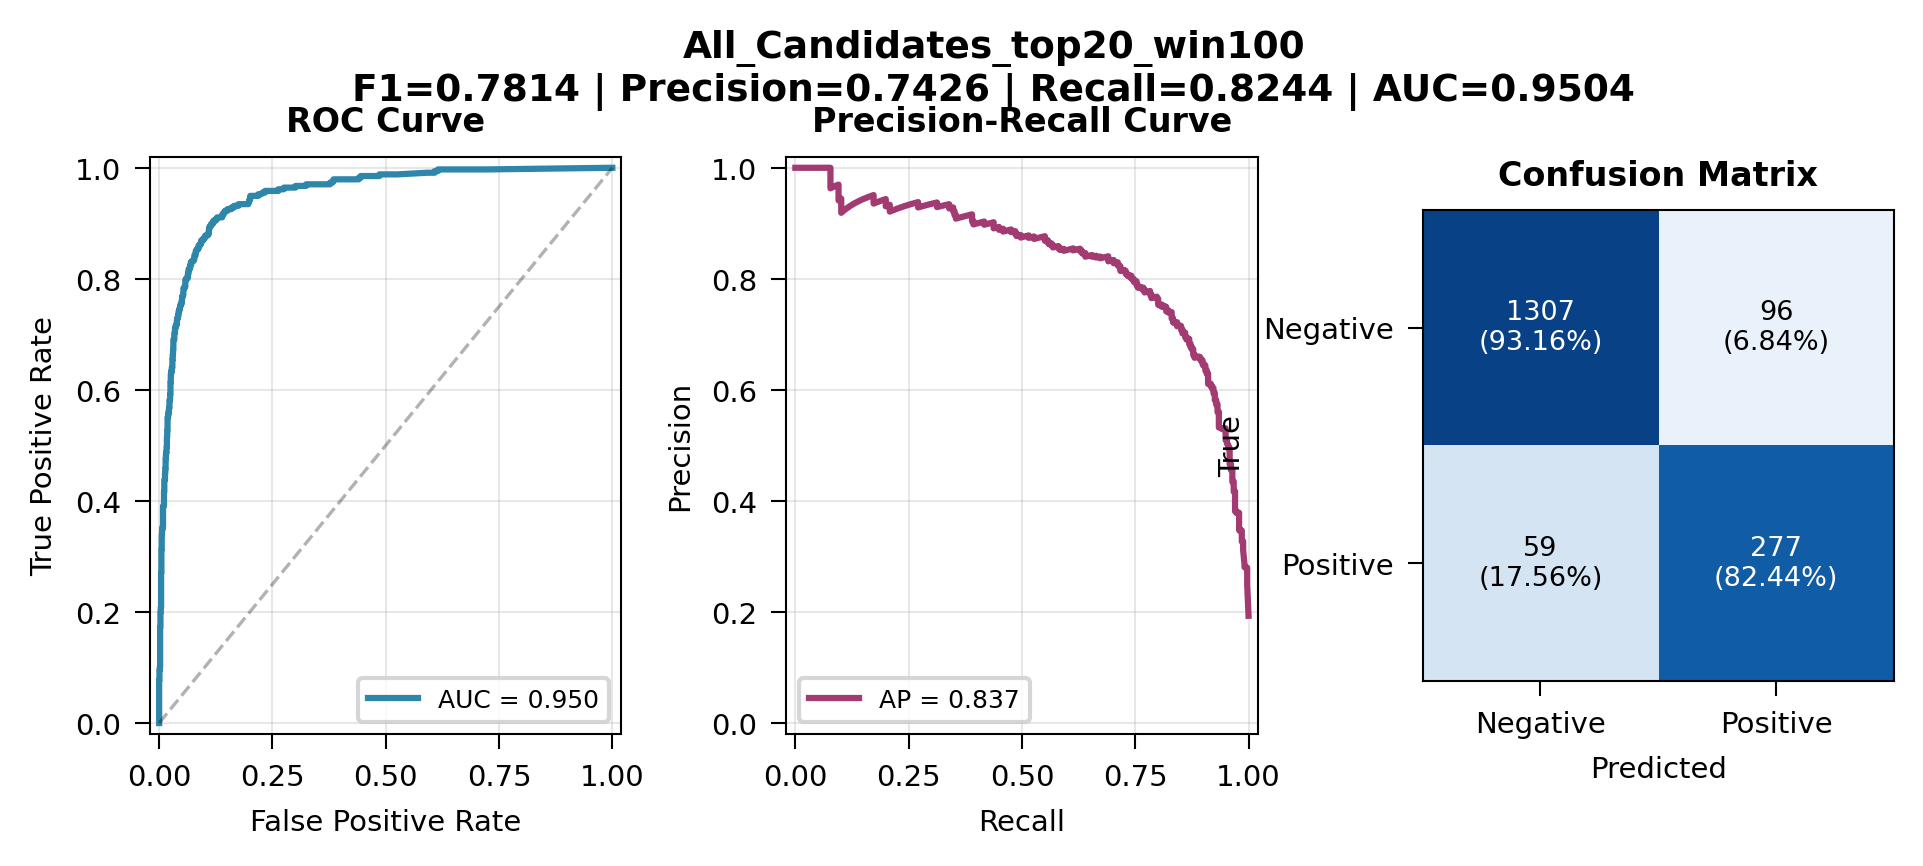

All Candidates (top-20, 150px): 336 pos, 3556 neg


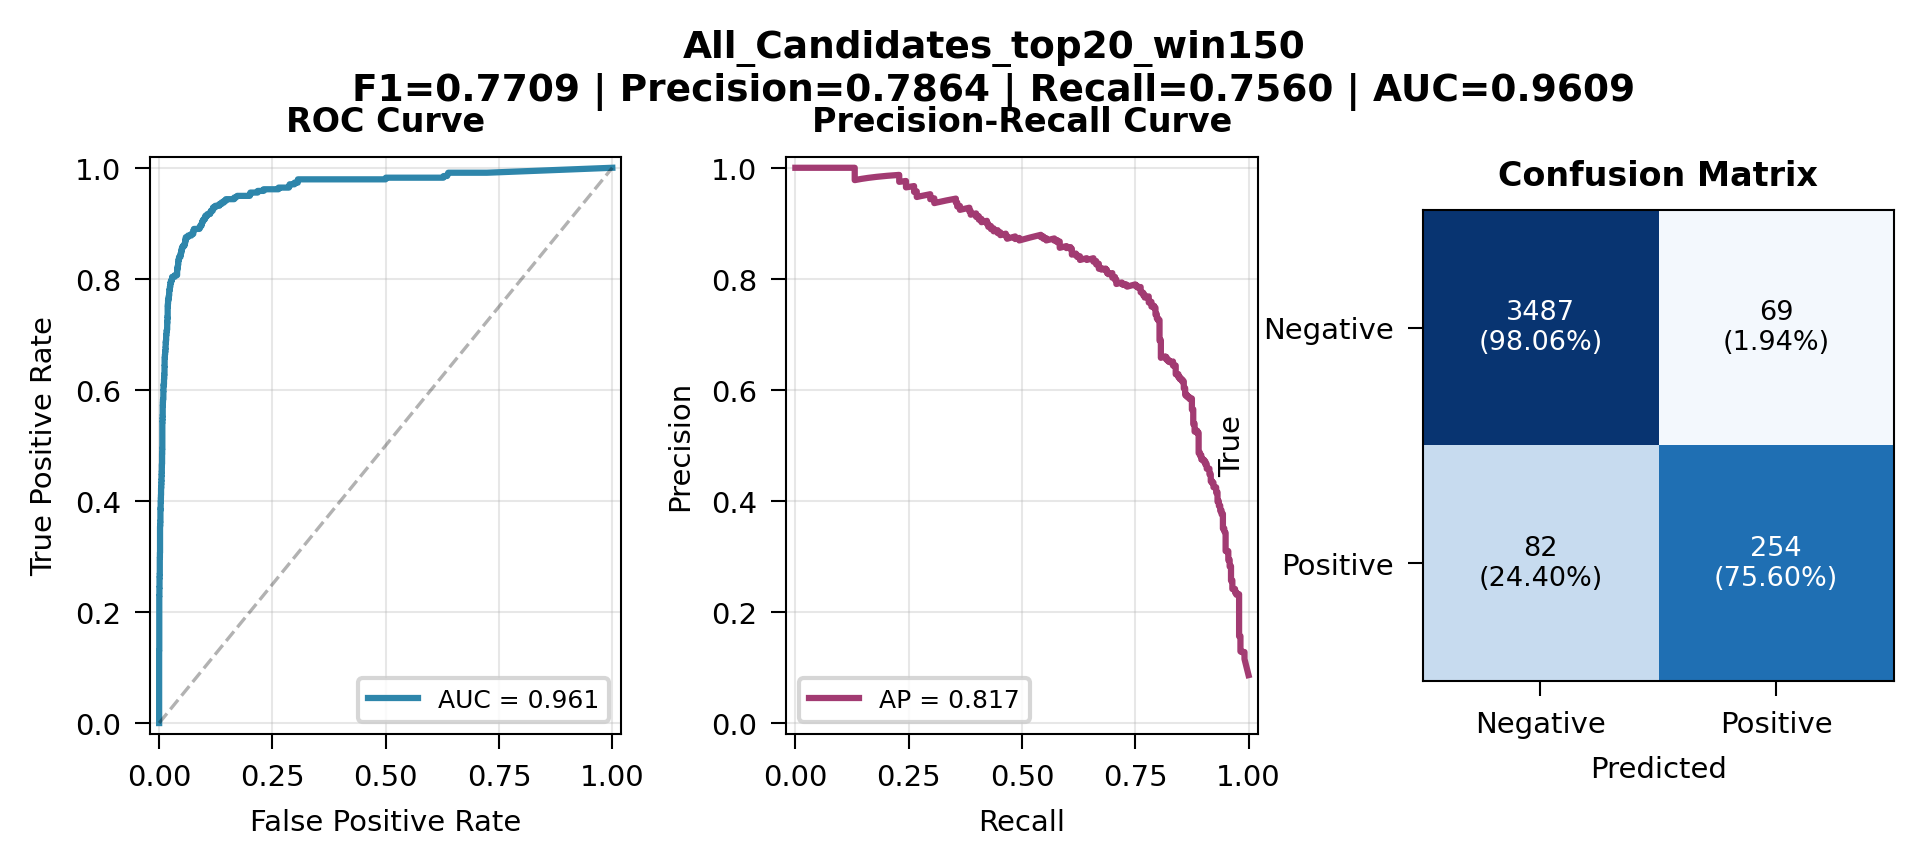

In [15]:
for top_n, window_size in ALL_CANDIDATES_CONFIGS:
    df = construct_dataset_all_candidates(golden_df, cells_by_slice, top_n=top_n, window_size=window_size)
    res = evaluate_strategy(df, f"All_Candidates_top{top_n}_win{window_size}", output_dir=OUTPUT_DIR)
    results.append(res)

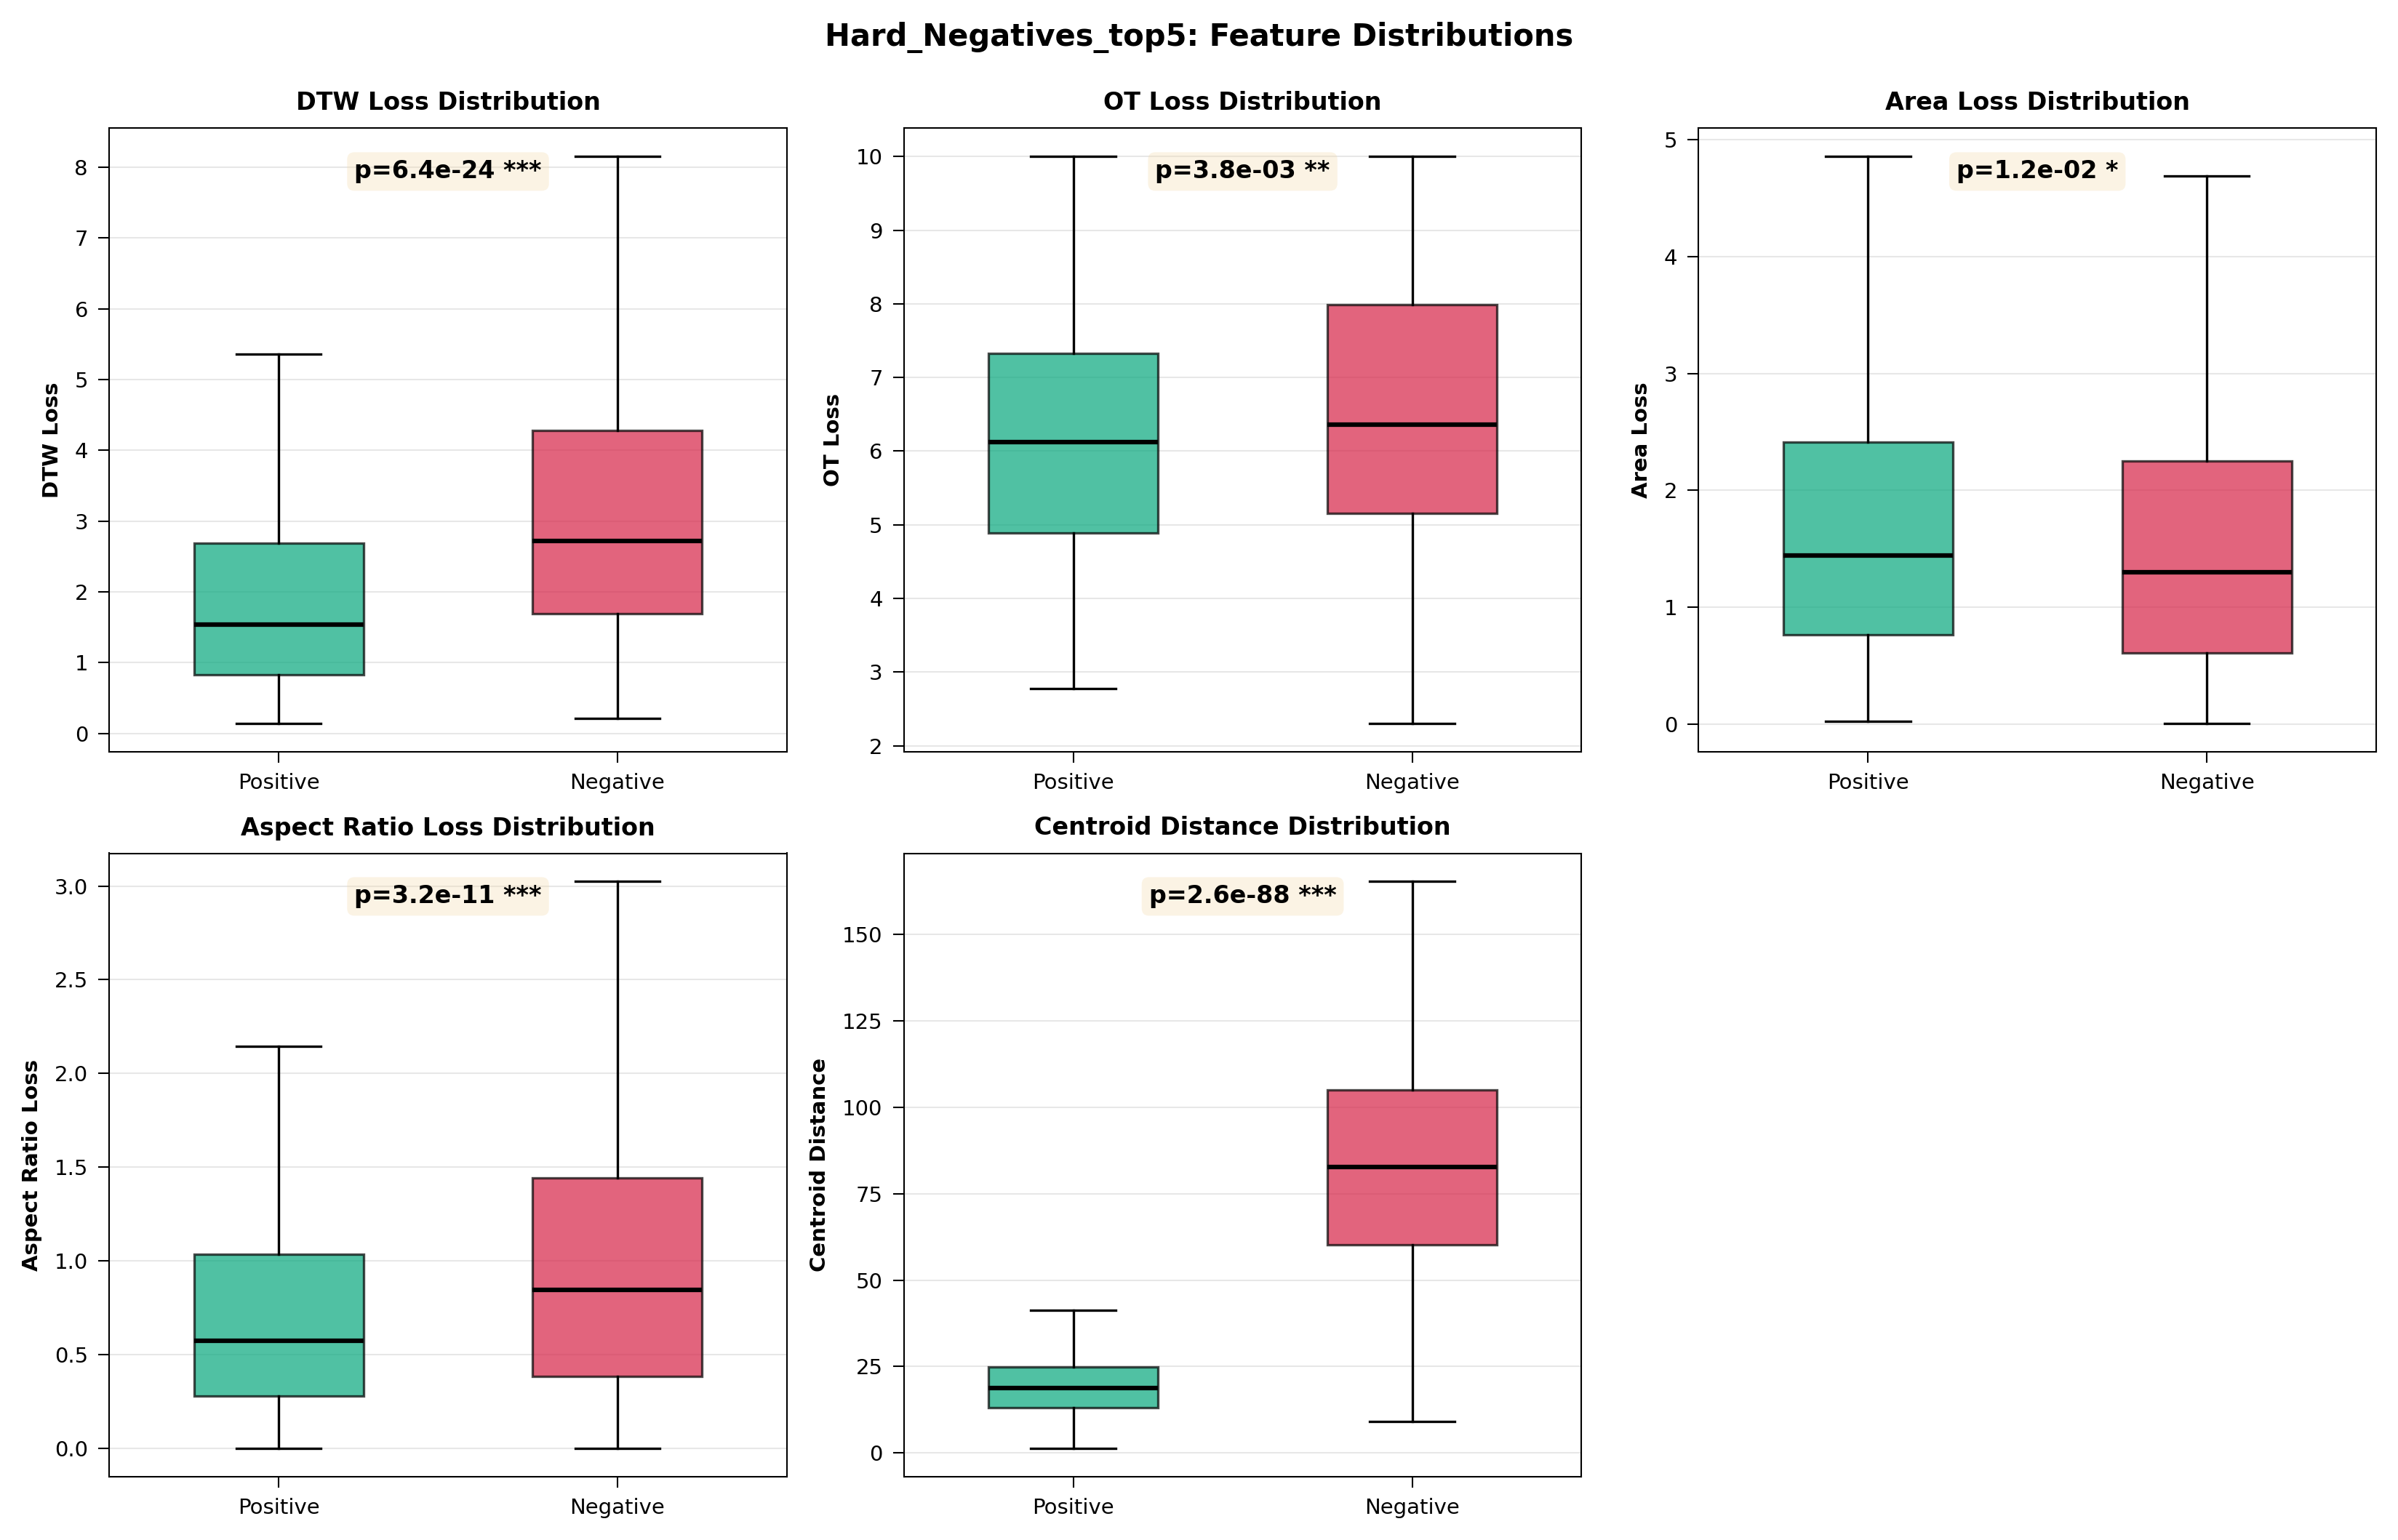

In [16]:
analyze_positive_negative_distributions(datasets["Hard_Negatives_top5"], "Hard_Negatives_top5", OUTPUT_DIR)

In [17]:
results_df = pd.DataFrame(results)
results_df

,strategy,n_samples,n_positive,n_negative,pos_neg_ratio,optimal_threshold,accuracy,precision,recall,f1,auc
0,Hard_Negatives_top5,2016,336,1680,1:5.0,0.45,0.944940,0.831858,0.839286,0.835556,0.954800
1,Hard_Negatives_top10,3696,336,3360,1:10.0,0.45,0.965639,0.797721,0.833333,0.815138,0.970312
2,Hard_Negatives_top20,7056,336,6720,1:20.0,0.45,0.981293,0.783333,0.839286,0.810345,0.976099
3,All_Candidates_top20_win100,1739,336,1403,1:4.2,0.35,0.910868,0.742627,0.824405,0.781382,0.950373
4,All_Candidates_top20_win150,3892,336,3556,1:10.6,0.50,0.961202,0.786378,0.755952,0.770865,0.960942


In [18]:
best_idx = results_df["f1"].idxmax()
print(f"Best strategy: {results_df.loc[best_idx, 'strategy']} (F1={results_df.loc[best_idx, 'f1']:.4f})")

Best strategy: Hard_Negatives_top5 (F1=0.8356)


In [ ]:
# End of analysis